In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

# Using Numerical Data

In [5]:
df = pd.read_csv('Data/train.csv', usecols = ['Age','Fare','Survived'])

In [7]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [8]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [9]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 2)

In [47]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [48]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,NaN
493,71.0,49.5042,71.0
527,NaN,221.7792,NaN


In [49]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()] 

77    NaN
868   NaN
334   NaN
295   NaN
792   NaN
       ..
674   NaN
466   NaN
584   NaN
527   NaN
168   NaN
Name: Age_imputed, Length: 148, dtype: float64

In [50]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

array([ 3.  , 54.  , 24.  , 20.  , 32.  , 29.  , 20.  , 16.  , 32.  ,
       19.  , 30.  , 29.  , 36.  , 44.  , 20.  ,  0.67,  5.  , 48.  ,
       22.  , 24.  , 37.  , 25.  ,  0.75, 17.  ,  9.  , 25.  , 34.  ,
       33.  , 31.  , 52.  , 23.  , 38.  , 32.  , 49.  , 42.  , 23.  ,
       28.  , 22.  , 32.  , 45.  , 33.  , 33.  , 47.  ,  7.  , 26.  ,
        3.  , 35.  , 18.  , 31.  , 38.  , 20.  , 19.  , 25.  , 24.  ,
       20.  , 36.  , 17.  ,  9.  , 39.  , 18.  ,  0.83, 36.  , 22.  ,
       39.  , 27.  , 29.  , 18.  , 50.  ,  4.  , 62.  , 22.  , 30.  ,
        9.  , 30.  , 53.  , 40.  , 45.  , 26.  , 30.  , 30.  , 16.  ,
       42.  , 42.  ,  7.  , 22.  , 36.  , 28.  , 19.  , 33.  , 51.  ,
       60.  , 18.  , 23.5 , 29.  , 32.  , 21.  , 25.  , 17.  , 29.  ,
        1.  , 58.  , 25.  , 26.  , 34.  ,  8.  , 36.  , 16.  , 31.  ,
       39.  ,  4.  , 45.  , 24.  , 49.  , 28.  , 31.  , 47.  , 34.  ,
       24.  , 19.  , 34.5 , 42.  , 51.  , 22.  , 14.  , 40.  , 12.  ,
       42.  , 16.  ,

In [51]:
X_train.loc[X_train['Age_imputed'].isnull(), 'Age_imputed'] = X_train['Age'].dropna().sample(
    X_train['Age'].isnull().sum(), 
    random_state = 45
).values

X_test.loc[X_test['Age_imputed'].isnull(), 'Age_imputed'] = X_train['Age'].dropna().sample(
    X_test['Age'].isnull().sum(), 
    random_state = 45
).values

In [52]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,28.0
493,71.0,49.5042,71.0
527,NaN,221.7792,24.0


C:\Users\jaggi\AppData\Local\Temp\ipykernel_12108\2098702694.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'], label = 'Orignal', hist = False)
C:\Users\jaggi\AppData\Local\Temp\ipykernel_12108\2098702694.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_t

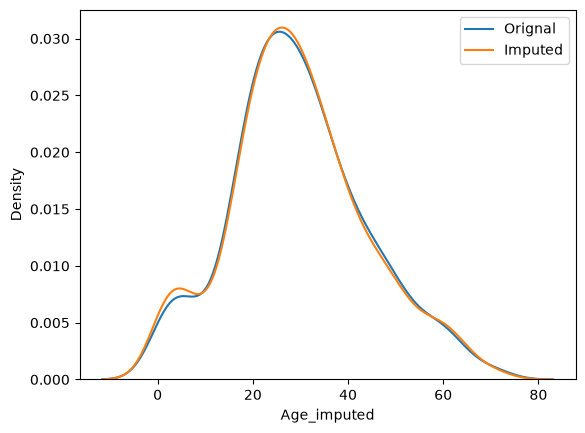

In [56]:
sns.distplot(X_train['Age'], label = 'Orignal', hist = False)
sns.distplot(X_train['Age_imputed'], label = 'Imputed', hist = False)

plt.legend()
plt.show()